<a href="https://colab.research.google.com/github/Narmadha-H/MLA0202-FML/blob/main/ML19.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Setup complete
   Age   Income  Loan_Amount  Credit_Score  Employment_Years  Dependents  \
0   24  40156.0      36774.0           430                11           2   
1   55  73487.0      32800.0           408                26           3   
2   49  55692.0       5224.0           502                13           0   
3   40  49344.0      13294.0           792                27           0   
4   40  52876.0      33599.0           721                 5           4   

   Married  Graduate  Loan_Status  
0        1         0            0  
1        1         1            0  
2        1         1            1  
3        0         1            1  
4        0         0            1  
Loan_Status
1    1187
0     813
Name: count, dtype: int64
Accuracy: 0.89
              precision    recall  f1-score   support

    Rejected       0.87      0.85      0.86       203
    Approved       0.90      0.92      0.91       297

    accuracy                           0.89       500
   macro avg       0.

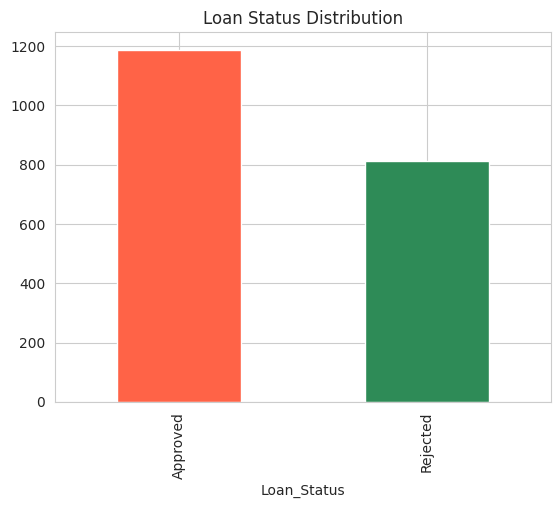

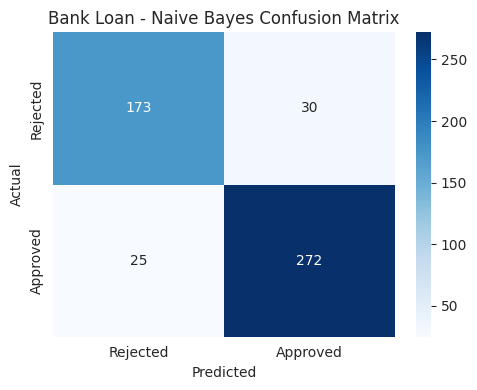

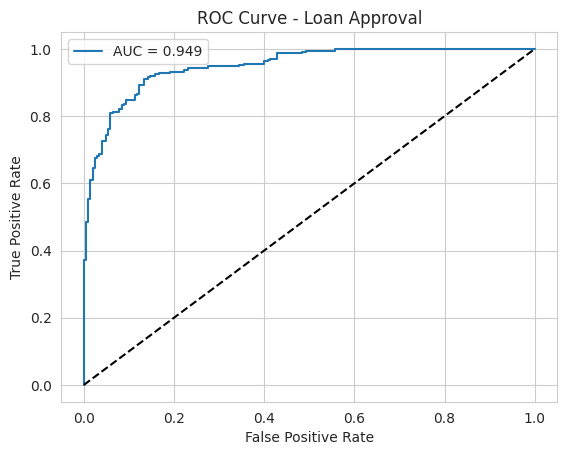

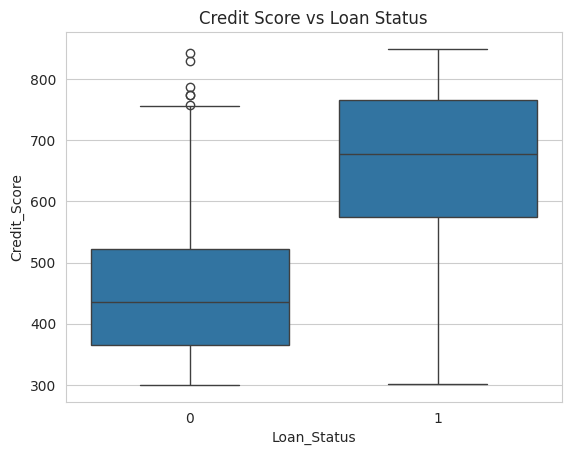

In [1]:
# ---------- Common imports and helper functions ----------
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import warnings; warnings.filterwarnings("ignore")

from sklearn.datasets import load_iris, load_breast_cancer, fetch_california_housing
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression, LogisticRegression, Perceptron as SkPerceptron
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.metrics import (accuracy_score, confusion_matrix, classification_report, roc_curve, auc,
                             r2_score, mean_squared_error, mean_absolute_error,
                             precision_score, recall_score, f1_score)

sns.set_style("whitegrid")
rng = np.random.default_rng(42)

def plot_cm(y_true, y_pred, labels, title):
    cm = confusion_matrix(y_true, y_pred)
    fig, ax = plt.subplots(figsize=(5, 4))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=labels, yticklabels=labels, ax=ax)
    ax.set_xlabel("Predicted"); ax.set_ylabel("Actual"); ax.set_title(title)
    plt.tight_layout(); plt.show()

def plot_reg(y_true, y_pred, title):
    y_true = np.asarray(y_true); y_pred = np.asarray(y_pred)
    fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
    ax[0].scatter(y_true, y_pred, alpha=0.5, color="steelblue")
    lims = [min(y_true.min(), y_pred.min()), max(y_true.max(), y_pred.max())]
    ax[0].plot(lims, lims, "r--", label="Perfect prediction")
    ax[0].set_xlabel("Actual"); ax[0].set_ylabel("Predicted"); ax[0].set_title(title); ax[0].legend()
    ax[1].hist(y_true - y_pred, bins=30, color="orange", edgecolor="black")
    ax[1].set_title("Residuals (Actual - Predicted)"); ax[1].set_xlabel("Error")
    plt.tight_layout(); plt.show()
    print(f"R2 = {r2_score(y_true, y_pred):.3f} | RMSE = {np.sqrt(mean_squared_error(y_true, y_pred)):.3f} | MAE = {mean_absolute_error(y_true, y_pred):.3f}")

def plot_importance(names, values, title):
    s = pd.Series(values, index=names).sort_values()
    s.plot(kind="barh", figsize=(7, 4), color="teal"); plt.title(title); plt.xlabel("Importance")
    plt.tight_layout(); plt.show()

def plot_boundary(model, X2, y, xlabel, ylabel, class_names, title):
    # model must already be trained on the 2 features in X2
    x_min, x_max = X2[:, 0].min() - 0.5, X2[:, 0].max() + 0.5
    y_min, y_max = X2[:, 1].min() - 0.5, X2[:, 1].max() + 0.5
    xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.02), np.arange(y_min, y_max, 0.02))
    Z = model.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    plt.figure(figsize=(6, 5))
    plt.contourf(xx, yy, Z, alpha=0.25, cmap="viridis")
    for i, c in enumerate(class_names):
        plt.scatter(X2[y == i, 0], X2[y == i, 1], label=c, edgecolor="k")
    plt.xlabel(xlabel); plt.ylabel(ylabel); plt.title(title); plt.legend(); plt.show()
print("Setup complete")

n = 2000
df = pd.DataFrame({
    "Age": rng.integers(21, 65, n),
    "Income": rng.normal(55000, 20000, n).clip(15000, None).round(),
    "Loan_Amount": rng.uniform(5000, 50000, n).round(),
    "Credit_Score": rng.integers(300, 850, n),
    "Employment_Years": rng.integers(0, 30, n),
    "Dependents": rng.integers(0, 5, n),
    "Married": rng.choice([0, 1], n),
    "Graduate": rng.choice([0, 1], n, p=[.3, .7]),
})
logit = (0.012*(df.Credit_Score - 575) + 0.00005*(df.Income - 55000) - 0.00008*(df.Loan_Amount - 27500)
         + 0.05*df.Employment_Years + 0.4*df.Graduate - 0.15*df.Dependents + rng.normal(0, 0.8, n))
df["Loan_Status"] = (1 / (1 + np.exp(-logit)) > 0.5).astype(int)     # 1 = Approved
print(df.head()); print(df["Loan_Status"].value_counts())

X = df.drop(columns="Loan_Status"); y = df["Loan_Status"]
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)
nb = GaussianNB().fit(X_tr, y_tr)
pred = nb.predict(X_te); prob = nb.predict_proba(X_te)[:, 1]
print("Accuracy:", round(accuracy_score(y_te, pred), 3)); print(classification_report(y_te, pred, target_names=["Rejected", "Approved"]))

df["Loan_Status"].map({0: "Rejected", 1: "Approved"}).value_counts().plot(kind="bar", color=["tomato", "seagreen"], title="Loan Status Distribution")
plt.show()
plot_cm(y_te, pred, ["Rejected", "Approved"], "Bank Loan - Naive Bayes Confusion Matrix")
fpr, tpr, _ = roc_curve(y_te, prob)
plt.plot(fpr, tpr, label=f"AUC = {auc(fpr, tpr):.3f}"); plt.plot([0, 1], [0, 1], "k--")
plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate"); plt.title("ROC Curve - Loan Approval"); plt.legend(); plt.show()
sns.boxplot(x="Loan_Status", y="Credit_Score", data=df); plt.title("Credit Score vs Loan Status"); plt.show()